<a href="https://colab.research.google.com/github/Roman74800/banking-ab-test/blob/main/analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Banking onboarding A/B test
Reproducible randomized synthetic experiment; no real bank data.

fatal: destination path 'banking-ab-test' already exists and is not an empty directory.
/content/banking-ab-test/experiment.csv
           users  conversions    revenue  conversion        arpu
variant                                                         
control     5965         1126  781243.82    0.188768  130.971303
treatment   6035         1303  909754.87    0.215907  150.746457
Absolute lift: 2.71%; relative lift: 14.38%
Two-sided pooled z-test: z=3.699, p=0.0002
95% CI for absolute lift (Wald): [1.28%, 4.15%]
Decision at alpha=0.05: statistically significant


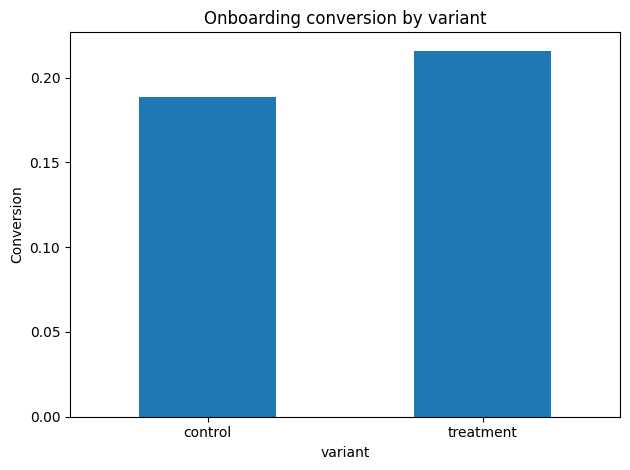

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from pathlib import Path
!git clone https://github.com/Roman74800/banking-ab-test.git
!find /content/banking-ab-test -name "*.csv"
path=Path('../data/experiment.csv') if Path('../data/experiment.csv').exists() else Path('data/experiment.csv')
df = pd.read_csv('/content/banking-ab-test/experiment.csv')
summary=df.groupby('variant').agg(users=('user_id','nunique'),conversions=('completed','sum'),revenue=('revenue_rub','sum'))
summary['conversion']=summary.conversions/summary.users
summary['arpu']=summary.revenue/summary.users
print(summary)
c,t=summary.loc['control'],summary.loc['treatment']
pool=(c.conversions+t.conversions)/(c.users+t.users)
se_null=np.sqrt(pool*(1-pool)*(1/c.users+1/t.users))
diff=t.conversion-c.conversion
z=diff/se_null
p_value=2*norm.sf(abs(z))
se_ci=np.sqrt(c.conversion*(1-c.conversion)/c.users+t.conversion*(1-t.conversion)/t.users)
ci=(diff-1.96*se_ci,diff+1.96*se_ci)
print(f'Absolute lift: {diff:.2%}; relative lift: {diff/c.conversion:.2%}')
print(f'Two-sided pooled z-test: z={z:.3f}, p={p_value:.4f}')
print(f'95% CI for absolute lift (Wald): [{ci[0]:.2%}, {ci[1]:.2%}]')
print('Decision at alpha=0.05:', 'statistically significant' if p_value<.05 else 'not statistically significant')
summary.conversion.plot.bar(rot=0,title='Onboarding conversion by variant');plt.ylabel('Conversion');plt.tight_layout();plt.show()


## Product recommendation framework
Ship only if the primary metric and guardrails meet pre-registered criteria, the experiment has adequate power, and operational costs are acceptable. A non-significant result is not proof of no effect.